# SAE "Analyse automatique de données" -- Notebook 4 : régression linéaire

Dans ce notebook, vous devez :
1. Effectuer des expérimentations pour optimiser les paramètres du modèle de régression linéaire ;
2. Rédiger une synthèse pour justifier des pré-traitements effectués et des valeurs des paramètres obtenus pour vos modèles de régression. Vous concluerez sur le meilleur choix des pré-traitements et des paramètres de votre ou vos modèles.

	
Vous pouvez également tout d'abord considérer un sous-ensemble de votre ensemble d'apprentissage, pour mettre au point chacune de vos expérimentations.
			


## Modules python utilisés

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, r2_score, root_mean_squared_error
import math
import spacy
import numpy as np


## 0. Traitements des données

In [ ]:
# Spacy

# Charge la langue - anglais
# Attention: Nous avons choisi la version sm de la bibliothèque, la version trf peut être prise cependant elle plus volumineuse et plus lente
nlp = spacy.load("en_core_web_sm")

def cleanData(doc):
    doc = doc.lower()
    doc = nlp(doc)
    tokens_utiles = [
        token.lemma_.lower() for token in doc
        if not token.is_stop and not token.is_punct 
        and token.pos_ in ["ADJ","ADV","VERB"] # 
    ]
    
    return " ".join(tokens_utiles)

def cleanAllData(docs):
    clean_data = []
    for doc in docs:
        clean_data.append(cleanData(doc))

print(cleanData(fake_review_df['text_'].iloc[0]))


fake_review_df['text_'] = fake_review_df['text_'].map(lambda x: cleanData(x))
fake_review_df['text_'].replace("", np.nan, inplace=True)

avant_dropNa = len(fake_review_df)
fake_review_df = fake_review_df.dropna(subset=['text_'])
apres_dropNa = len(fake_review_df)

print(f"Traitement spacy terminé {avant_dropNa - apres_dropNa} lignes vides supprimés ")


## 1. Régression linéaire

In [ ]:
#Df d'apprentissage
x_train = pd.read_csv('data/train_test/x_train.csv',  index_col=0)
y_train = pd.read_csv('data/train_test/y_train.csv',  index_col=0)

#Df de test
x_test = pd.read_csv('data/train_test/x_test.csv',  index_col=0)
y_test = pd.read_csv('data/train_test/y_test.csv',  index_col=0)


### 1.1 Régression avec le texte - Linear Regression

Processeur : drop
Mse: 1.6758785777556364
RMSE: 1.2945572902562623


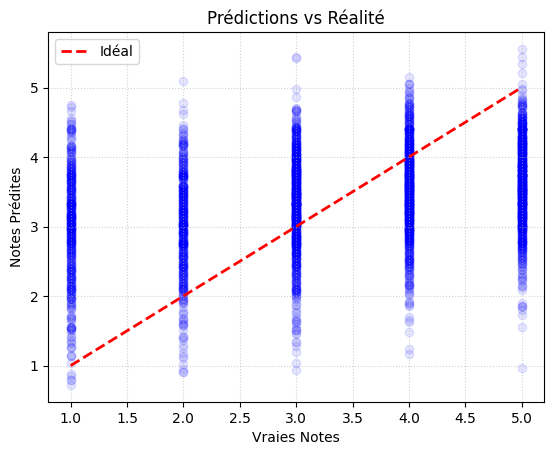

In [ ]:
# On défini les différents transformeurs 
processeur = ColumnTransformer(
    remainder='drop',
    transformers=[
        ('review', TfidfVectorizer(
            max_features=5000, # Garder les X termes plus importants
            min_df=10, # Ignorer les mots avec une rareté inférieur à 10
            ngram_range=(1,2), # Capte les expressions de 2 mots monogramme et bigramme
            stop_words='english'), 
         'text_'),
    ]
)

print(f"Processeur : {processeur.remainder}")

model = Pipeline([
    ('preprocessor', processeur),
    ('classifier', LinearRegression())
])

reg = model.fit(X=x_train,y=y_train)

prediction = reg.predict(x_test)

mse = mean_squared_error(y_test,prediction)

print(f"Mse: {mse}")
print(f"RMSE: {math.sqrt(mse)}")

plt.scatter(y_test, prediction, color='blue', alpha=0.1)

plt.plot([1, 5], [1, 5], color='red', linestyle='--', linewidth=2, label='Idéal')

plt.title('Prédictions vs Réalité')
plt.xlabel('Vraies Notes')
plt.ylabel('Notes Prédites')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)


### 1.2 Régression avec le texte - Ridge

Processeur : drop
Mse: 1.5826334644237665
RMSE: 1.2580276087684907


'\nOn constate que sans utiliser de paramètres dans TfidVectorizer on obtient une RMSE de 1.16 au lieu de 1.18\nLes paramères utilisés:\n\n'

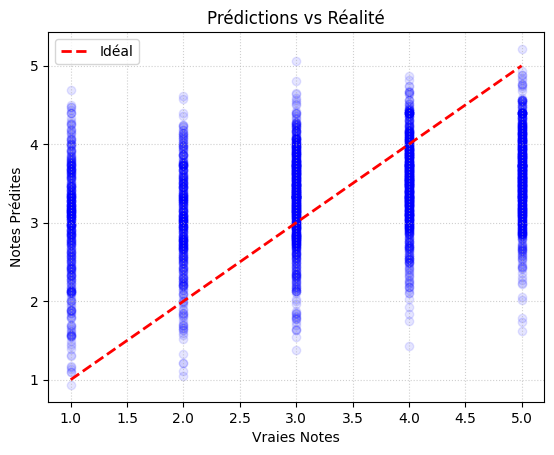

In [ ]:
# On défini les différents transformeurs 
processeur = ColumnTransformer(
    remainder='drop',
    transformers=[
        ('review', TfidfVectorizer(max_features=5000, # Garder les X termes plus importants
            min_df=10, # Ignorer les mots avec une rareté inférieur à 5
            ngram_range=(1,2), # Capte les expressions de 2 mots
            stop_words='english'), 
         'text_'),
    ]
)

print(f"Processeur : {processeur.remainder}")

model = Pipeline([
    ('preprocessor', processeur),
    ('classifier', Ridge())
])

reg = model.fit(X=x_train,y=y_train)

prediction = reg.predict(x_test)

mse = mean_squared_error(y_test,prediction)

print(f"Mse: {mse}")
print(f"RMSE: {math.sqrt(mse)}")


plt.scatter(y_test, prediction, color='blue', alpha=0.1)

plt.plot([1, 5], [1, 5], color='red', linestyle='--', linewidth=2, label='Idéal')

plt.title('Prédictions vs Réalité')
plt.xlabel('Vraies Notes')
plt.ylabel('Notes Prédites')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)

"""
 Les paramères utilisés:

"""

## 2. Synthèse des expérimentations et des résultats obtenus